# Tugas Praktikum 2: Praproses Data

| Informasi | Detail |
| --- | --- |
| **Nama** | Rasya Arya Ramadhan |
| **NRP** | 5054251019 |
| **Mata Kuliah** | Data Mining |
| **Dataset** | House Prices - Advanced Regression Techniques (Kaggle `train.csv`) |


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## 1. Unduh dan Import Dataset

Dataset yang digunakan adalah `train.csv` dari kompetisi Kaggle *House Prices: Advanced Regression Techniques*. Dataset ini berisi 1.460 observasi rumah dengan 81 atribut (termasuk variabel target `SalePrice`).


In [2]:
file_path = 'train.csv'
df = pd.read_csv(file_path)

print("Dimensi dataset awal:", df.shape[0], "baris x", df.shape[1], "kolom")
print("\n--- 5 Baris Pertama Dataset ---")
print(df.head())
print("\n--- Ringkasan Informasi Dataset (.info()) ---")
df.info(verbose=False)


Dimensi dataset awal: 1460 baris x 81 kolom

--- 5 Baris Pertama Dataset ---
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities LotConfig LandSlope Neighborhood Condition1  \
0         Lvl    AllPub    Inside       Gtl      CollgCr       Norm   
1         Lvl    AllPub       FR2       Gtl      Veenker      Feedr   
2         Lvl    AllPub    Inside       Gtl      CollgCr       Norm   
3         Lvl    AllPub    Corner       Gtl      Crawfor       Norm   
4         Lvl    AllPub       FR2       Gtl      NoRidge       Norm   

  Condition2 BldgType HouseStyle  OverallQual  Over

## 2. Pembersihan Data (Data Cleaning)

Tahap ini mencakup:
1. Pemeriksaan nilai hilang (*missing values*) pada seluruh atribut.
2. Penghapusan atribut dengan proporsi nilai hilang lebih dari 50%.
3. Imputasi nilai hilang pada atribut tersisa sesuai dengan jenis data dan konteks bisnis.


In [3]:
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100

missing_df = pd.DataFrame({
    'Jumlah Missing': missing_count[missing_count > 0],
    'Persentase (%)': missing_pct[missing_pct > 0]
}).sort_values(by='Persentase (%)', ascending=False)

print("--- Atribut dengan Missing Value > 50% ---")
over_50 = missing_df[missing_df['Persentase (%)'] > 50]
print(over_50)

cols_to_drop_50 = over_50.index.tolist()
df_clean = df.drop(columns=cols_to_drop_50)

print(f"\nKolom yang dihapus (>50% missing): {cols_to_drop_50}")
print(f"Dimensi dataset setelah menghapus kolom >50% missing: {df_clean.shape}")


--- Atribut dengan Missing Value > 50% ---
             Jumlah Missing  Persentase (%)
PoolQC                 1453       99.520548
MiscFeature            1406       96.301370
Alley                  1369       93.767123
Fence                  1179       80.753425
MasVnrType              872       59.726027

Kolom yang dihapus (>50% missing): ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType']
Dimensi dataset setelah menghapus kolom >50% missing: (1460, 76)


In [4]:
cat_facility_cols = [
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond'
]
for col in cat_facility_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('None')

if 'GarageYrBlt' in df_clean.columns:
    df_clean['GarageYrBlt'] = df_clean['GarageYrBlt'].fillna(0)

df_clean['LotFrontage'] = df_clean.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))
df_clean['LotFrontage'] = df_clean['LotFrontage'].fillna(df_clean['LotFrontage'].median())

if 'MasVnrArea' in df_clean.columns:
    df_clean['MasVnrArea'] = df_clean['MasVnrArea'].fillna(0)

if 'Electrical' in df_clean.columns:
    df_clean['Electrical'] = df_clean['Electrical'].fillna(df_clean['Electrical'].mode()[0])

remaining_nulls = df_clean.isnull().sum().sum()
print(f"Jumlah total missing value setelah imputasi: {remaining_nulls}")


Jumlah total missing value setelah imputasi: 0


## 3. Deteksi dan Penanganan Outlier

Deteksi outlier dilakukan pada atribut numerik utama (`GrLivArea`, `SalePrice`, `TotalBsmtSF`, `LotArea`) menggunakan teknik visualisasi Boxplot.

Berdasarkan dokumentasi resmi dataset Ames Housing (De Cock, 2011), terdapat 2 observasi ekstrem pada `GrLivArea` (> 4.000 sq ft) yang dijual dengan harga sangat rendah (< $200.000). Observasi ini merupakan anomali parsial yang dapat merusak analisis dan estimasi model, sehingga perlu dihapus.


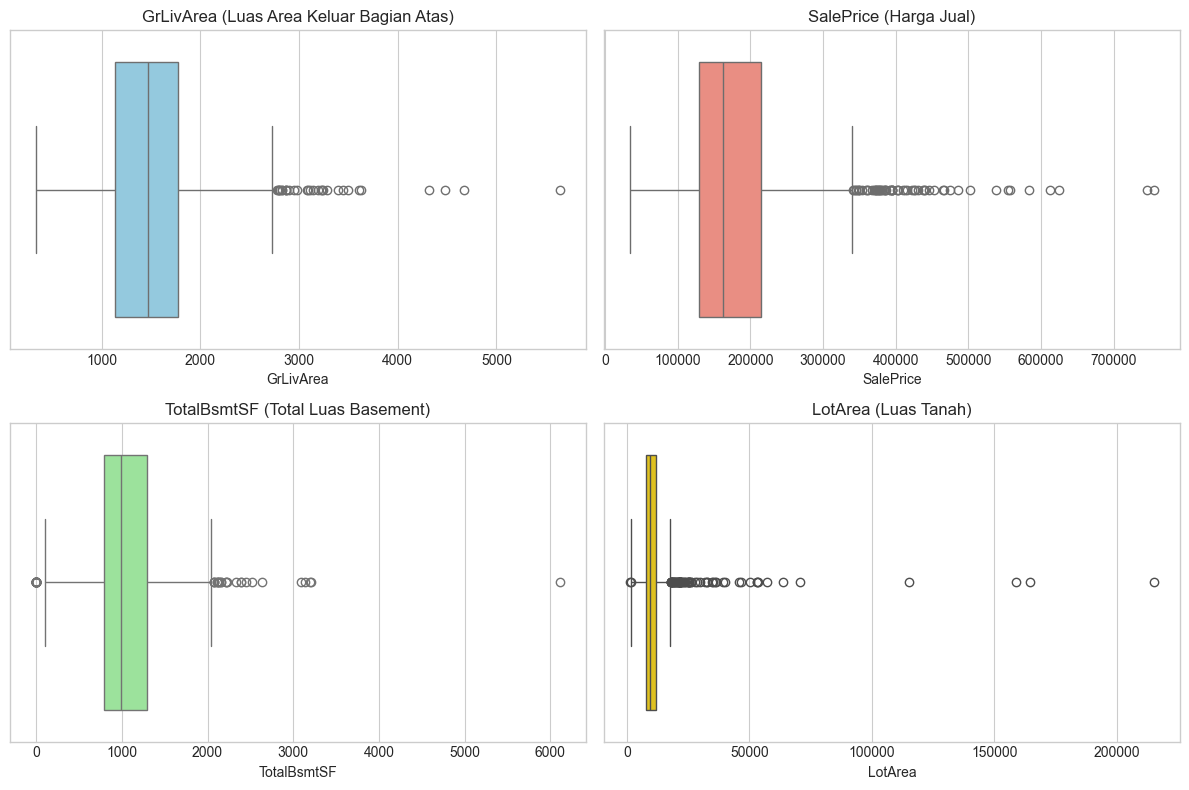

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.boxplot(x=df_clean['GrLivArea'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('GrLivArea (Luas Area Keluar Bagian Atas)')

sns.boxplot(x=df_clean['SalePrice'], ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('SalePrice (Harga Jual)')

sns.boxplot(x=df_clean['TotalBsmtSF'], ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('TotalBsmtSF (Total Luas Basement)')

sns.boxplot(x=df_clean['LotArea'], ax=axes[1, 1], color='gold')
axes[1, 1].set_title('LotArea (Luas Tanah)')

plt.tight_layout()
plt.show()


In [6]:
outlier_condition = (df_clean['GrLivArea'] > 4000) & (df_clean['SalePrice'] < 300000)
outlier_indices = df_clean[outlier_condition].index

print("Observasi outlier ekstrem yang teridentifikasi:")
print(df_clean.loc[outlier_indices, ['Id', 'GrLivArea', 'SalePrice']])

df_no_outliers = df_clean.drop(index=outlier_indices).reset_index(drop=True)
print(f"\nDimensi dataset setelah menghapus outlier: {df_no_outliers.shape}")


Observasi outlier ekstrem yang teridentifikasi:
        Id  GrLivArea  SalePrice
523    524       4676     184750
1298  1299       5642     160000

Dimensi dataset setelah menghapus outlier: (1458, 76)


## 4. Transformasi Data

Langkah transformasi meliputi:
1. **Pembersihan Fitur Redundan (Multikolinearitas Tinggi):** Mengidentifikasi pasangan fitur numerik dengan korelasi Pearson > 0,80 dan membuang salah satu atributnya agar tidak menimbulkan redundansi data.
2. **One-Hot Encoding:** Mengubah variabel kategorikal menjadi bentuk biner (`0` dan `1`) menggunakan `pd.get_dummies()`.
3. **Standarisasi Fitur:** Mengubah skala variabel numerik agar memiliki mean = 0 dan varians = 1 menggunakan `StandardScaler()`.


In [7]:
num_cols = df_no_outliers.select_dtypes(include=[np.number]).columns.drop(['Id', 'SalePrice'])
corr_matrix = df_no_outliers[num_cols].corr().abs()

high_corr_pairs = []
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        col1, col2 = num_cols[i], num_cols[j]
        val = corr_matrix.loc[col1, col2]
        if val > 0.80:
            high_corr_pairs.append((col1, col2, val))

print("--- Pasangan Fitur dengan Korelasi > 0.80 ---")
for c1, c2, val in high_corr_pairs:
    print(f"{c1} <-> {c2}: {val:.4f}")

redundant_cols = ['GarageArea', 'TotRmsAbvGrd', '1stFlrSF']
df_transformed = df_no_outliers.drop(columns=redundant_cols)

print(f"\nFitur redundan yang dihapus: {redundant_cols}")
print(f"Dimensi dataset setelah eliminasi fitur redundan: {df_transformed.shape}")


--- Pasangan Fitur dengan Korelasi > 0.80 ---
TotalBsmtSF <-> 1stFlrSF: 0.8038
GrLivArea <-> TotRmsAbvGrd: 0.8295
GarageCars <-> GarageArea: 0.8873

Fitur redundan yang dihapus: ['GarageArea', 'TotRmsAbvGrd', '1stFlrSF']
Dimensi dataset setelah eliminasi fitur redundan: (1458, 73)


In [8]:
y = df_transformed['SalePrice']
X = df_transformed.drop(columns=['Id', 'SalePrice'])

X_encoded = pd.get_dummies(X, drop_first=True, dtype=float)
print(f"Jumlah fitur setelah One-Hot Encoding: {X_encoded.shape[1]}")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_encoded.columns)

print(f"Dimensi matriks fitur setelah standarisasi: {X_scaled_df.shape}")


Jumlah fitur setelah One-Hot Encoding: 239
Dimensi matriks fitur setelah standarisasi: (1458, 239)


## 5. Reduksi Dimensi (Principal Component Analysis / PCA)

PCA digunakan untuk mengompresi matriks fitur berdimensi tinggi menjadi himpunan komponen utama (*Principal Components*) linier yang saling ortogonal, sembari mempertahankan sebagian besar variansi data.


Jumlah komponen utama untuk mempertahankan 90% variansi: 132
Jumlah komponen utama untuk mempertahankan 95% variansi: 155
Total komponen utama keseluruhan: 239


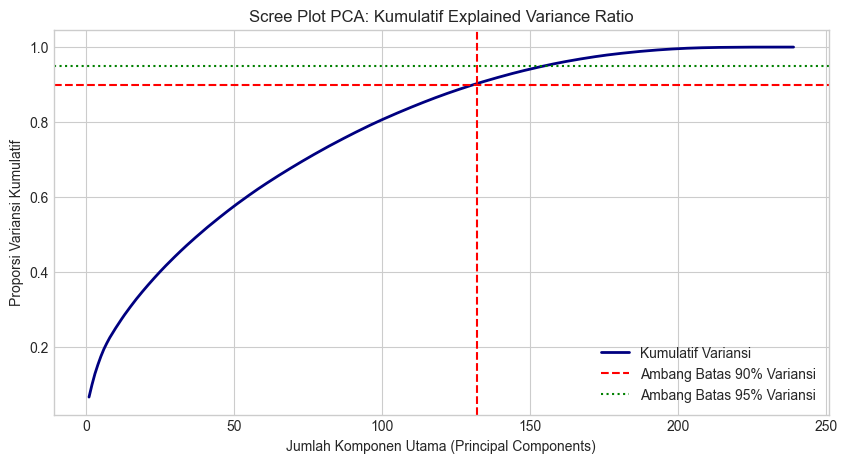

In [9]:
pca = PCA()
pca.fit(X_scaled)

cum_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_90 = np.argmax(cum_variance >= 0.90) + 1
n_components_95 = np.argmax(cum_variance >= 0.95) + 1

print(f"Jumlah komponen utama untuk mempertahankan 90% variansi: {n_components_90}")
print(f"Jumlah komponen utama untuk mempertahankan 95% variansi: {n_components_95}")
print(f"Total komponen utama keseluruhan: {len(cum_variance)}")

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker='', color='navy', linewidth=2, label='Kumulatif Variansi')
plt.axhline(y=0.90, color='red', linestyle='--', label='Ambang Batas 90% Variansi')
plt.axhline(y=0.95, color='green', linestyle=':', label='Ambang Batas 95% Variansi')
plt.axvline(x=n_components_90, color='red', linestyle='--')
plt.xlabel('Jumlah Komponen Utama (Principal Components)')
plt.ylabel('Proporsi Variansi Kumulatif')
plt.title('Scree Plot PCA: Kumulatif Explained Variance Ratio')
plt.legend()
plt.grid(True)
plt.show()


In [10]:
pca_final = PCA(n_components=n_components_90)
X_pca = pca_final.fit_transform(X_scaled)

pca_cols = [f'PC{i+1}' for i in range(n_components_90)]
df_pca = pd.DataFrame(X_pca, columns=pca_cols)

df_final = pd.concat([
    df_transformed[['Id']].reset_index(drop=True),
    df_pca,
    y.reset_index(drop=True)
], axis=1)

print(f"Dimensi akhir dataset setelah praproses & PCA: {df_final.shape}")
print("\n--- 5 Baris Pertama Dataset Hasil Praproses ---")
print(df_final.head())


Dimensi akhir dataset setelah praproses & PCA: (1458, 134)

--- 5 Baris Pertama Dataset Hasil Praproses ---
   Id       PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0   1  4.120819 -1.755782 -0.101571 -0.442370 -1.305873 -2.010813 -0.655027   
1   2  0.329010  2.943708  0.675008  1.650696  0.041787 -0.477534  0.382025   
2   3  4.956630 -1.364513  0.356734 -0.141946  0.276416 -1.909114 -0.339928   
3   4 -1.030757  0.268522 -0.869010 -2.586719  2.417321  0.943415  0.509968   
4   5  6.120700 -1.117317  0.689122 -0.075899  2.333638 -2.588552 -0.598064   

        PC8       PC9      PC10      PC11      PC12      PC13      PC14  \
0  2.455402 -0.907398  0.462086  0.689202 -0.032435 -0.764544  0.951682   
1  0.781759 -0.139216 -0.990271  1.935054  1.128994  0.070933  1.501857   
2  2.440211 -0.962889  0.499456  0.426969  0.050815 -0.545434  0.538524   
3 -0.105729 -1.758947 -0.532001 -0.760703 -0.410143  2.080187 -1.462932   
4  1.791508 -0.813928  1.331492  1.774221 

## 6. Ekspor Dataset Akhir

Dataset hasil praproses disimpan ke dalam berkas CSV sesuai dengan ketentuan format penamaan tugas praktikum.


In [11]:
output_csv_filename = '5054251019_Rasya Arya Ramadhan_Tugas_Praproses_Data.csv'
df_final.to_csv(output_csv_filename, index=False)

print(f"Dataset berhasil disimpan ke '{output_csv_filename}'")
print(f"Verifikasi ukuran dataset terformat: {df_final.shape[0]} baris x {df_final.shape[1]} kolom")


Dataset berhasil disimpan ke '5054251019_Rasya Arya Ramadhan_Tugas_Praproses_Data.csv'
Verifikasi ukuran dataset terformat: 1458 baris x 134 kolom
